In [3]:
%load_ext autoreload
%autoreload 2

from IPython.display import display

import warnings

import numpy as np
import pandas as pd

from thesis.analysis.analyse import (
    plot_overlaid_runs, 
    plot_behaviour_score_distributions, 
    step2_variance_decomposition,
)

from thesis.analysis.forecast import fit_and_forecast

from thesis.analysis.forecast_success_probs import (
    fit_success_probs, pinball_score, build_asr_probs_from_fit, 
    plot_success_prob_forecast_with_residuals
)

from thesis.analysis.plot_forecasts import (
    plot_cutoff_fits, 
    plot_fitted_curves, 
    plot_asr_forecast_assumptions, 
    plot_asr_forecast_vs_true, 
    plot_asr_compute_heatmap,
    plot_asr_decomposition,
    plot_asr_forecast_vs_observed_scatter_grid,
    build_asr_probs,
    compute_asr_at_k_cumulative,
    compute_asr_at_k,
    plot_asr_at_k_fit,
    plot_family_comparison_grid,
    _prettify,
    plot_overlaid_by_category,
    asr_at_k_forecast_error,
    plot_asr_mean_prob_vs_observed,
    plot_behaviours_by_failure_reason
)

from thesis.analysis.sign_flip_test import test_optimization

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", None)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Plots & Helpers

In [4]:
def load_forecast_run(forecast_run, list_passed_in_run, categories_by_number,
                       scores_dir="../data/scores", threshold=0.5):

    scores_cache_dir = f"{scores_dir}/{forecast_run}"
    all_scores = np.load(f"{scores_cache_dir}/all_scores.npy")

    mapping = {num: idx for idx, num in enumerate(list_passed_in_run)}
    categories_to_idx = {
        category: [mapping[num] for num in numbers] for category, numbers in categories_by_number.items()
    }

    # Calculate avg. harmfulness, hazard & ASR trajectories
    avg_harmfulness = np.nanmean(all_scores, axis=(1, 2))
    var_harmfulness = np.nanvar(all_scores, axis=(1, 2))
    success = np.where(np.isnan(all_scores), np.nan, (all_scores > threshold).astype(float))

    # Expected value of probability that sample i is larger than the threshold
    success_prob = np.nanmean(success, axis=(1, 2))          # (n_behaviors, n_steps)
    var_success = np.nanvar(success_prob, axis=(0))

    # Observed ASR
    any_sample_above = np.nanmax(success, axis=2)   # max over samples (axis=2) -> (problems, runs, steps)
    ever_valid = np.maximum.accumulate(~np.isnan(any_sample_above), axis=-1)
    cum_success = np.maximum.accumulate(np.nan_to_num(any_sample_above), axis=-1)
    observed_asr = np.nanmean(np.where(ever_valid, cum_success, np.nan), axis=1)  # (problems, steps)

    # Independent ASR
    per_step = np.nanmean(any_sample_above, axis=1)  # (problems, steps): P(any sample succeeds) at this step
    per_step_ever_valid = np.maximum.accumulate(~np.isnan(per_step), axis=1)
    independent_asr = np.where(per_step_ever_valid, 1 - np.nancumprod(1 - per_step, axis=1), np.nan)

    # Independent + Constant Success Prob ASR
    n_ref = max(1, round(0.2 * per_step.shape[1]))
    per_step_ref = np.nanmean(per_step[:, :n_ref], axis=1, keepdims=True)  # (problems, 1)
    step_valid = ~np.isnan(per_step)  # the real trajectory's own recording schedule
    per_step_const_full = np.where(step_valid, np.broadcast_to(per_step_ref, per_step.shape), np.nan)
    ref_valid = np.broadcast_to(~np.isnan(per_step_ref), per_step.shape)  # was the reference window itself defined?
    constant_hazard_asr = np.where(
        per_step_ever_valid & ref_valid, 1 - np.nancumprod(1 - per_step_const_full, axis=1), np.nan
    )

    print(all_scores.shape)
    print(success.shape)
    print(success_prob.shape)

    return {
        "all_scores": all_scores,
        "categories_to_idx": categories_to_idx,
        "avg_harmfulness": avg_harmfulness,
        "var_harmfulness": var_harmfulness,
        "success": success,
        "success_prob": success_prob,
        "var_success": var_success,
        "observed_asr": observed_asr,
        "independent_asr": independent_asr,
        "constant_hazard_asr": constant_hazard_asr,
    }


In [5]:
def summarize_fit_metrics(df, families=None, metrics=(), sort_by="in_sample_rmse", by_behaviour=True, ascending=True):
    """Compare `metrics` (plus `in_sample_rmse` and `converged`) across family x cutoff.

    Grouped by cutoff, with families ranked best-to-worst (ascending `sort_by` by default)
    within each group, so the best-fitting family per cutoff is immediately visible at the
    top of each block.

    `converged` is always included so the convergence rate for each (family, cutoff) is
    visible alongside the fit metrics -- a low-RMSE row backed by few converged fits is
    easy to miss otherwise.

    If `by_behaviour` (default), aggregate over individual behaviour rows (excluding
    `aggregate`): mean and median per (family, cutoff); the `converged` mean is the
    convergence rate. If False, use the `aggregate` row directly: one row per
    (family, cutoff) with the raw metric values, `converged` included as-is.
    """
    sub = df[df["row_id"] != "aggregate"] if by_behaviour else df[df["row_id"] == "aggregate"]
    if families is not None:
        sub = sub[sub["family"].isin(families)]
    cols = list(dict.fromkeys(["in_sample_rmse", "converged", *metrics]))

    if by_behaviour:
        summary = sub.groupby(["cutoff", "family"])[cols].agg(["mean", "median"])
        sort_key = (sort_by, "median")
    else:
        summary = sub.set_index(["cutoff", "family"])[cols]
        sort_key = sort_by

    summary = summary.sort_values(sort_key, ascending=ascending)
    return summary.sort_index(level="cutoff", sort_remaining=False, kind="stable")

# JR1 on LLama 3.1

In [6]:
FORECAST_RUN = "jr1_llama_100"

# Category mapping for shuffled indices (JR1)
original_idx = [21, 27, 37, 41, 42, 43, 44, 45, 46, 49, 50, 53, 58, 59, 60, 61, 66, 70, 76, 77, 84, 85, 86, 90, 111, 112, 115, 116, 121, 122, 123, 132, 141, 149, 170, 171, 172, 173, 174, 175]
list_passed_in_run = [37,124,159,41,111,32,0,148,20,150,39,85,40,199,62,10,89,48,182,191,14,114,128,50,152,109,90,12,154,87,54,186,15,19,42,168,104,188,155,110]
mapping = {num: list_passed_in_run[idx] for idx, num in enumerate(original_idx)}

categories_to_idx = {
    'misinformation': [mapping[num] for num in [170, 171, 172, 173, 174, 175, 121, 122, 115, 21]], 
    'offensive': [mapping[num] for num in [111, 112, 116, 123, 84, 86, 90, 132, 141, 149]], 
    'malicious_creation': [mapping[num] for num in [37, 42, 44, 49, 45, 50, 58, 59, 61, 46]], 
    'harmful_instruction': [mapping[num] for num in [85, 77, 76, 70, 66, 53, 43, 41, 60, 27]]
}

### For Llama
_loaded_llama = load_forecast_run("jr1_llama_100", list_passed_in_run, categories_to_idx)
all_scores_llama = _loaded_llama["all_scores"]
categories_to_idx_llama = _loaded_llama["categories_to_idx"]
avg_harmfulness_llama = _loaded_llama["avg_harmfulness"]
var_harmfulness_llama = _loaded_llama["var_harmfulness"]
success_llama = _loaded_llama["success"]
success_prob_llama = _loaded_llama["success_prob"]
var_success_llama = _loaded_llama["var_success"]

### For Gemma

_loaded_gemma = load_forecast_run("jr1_gemma_100", list_passed_in_run, categories_to_idx)
all_scores_gemma = _loaded_gemma["all_scores"]
avg_harmfulness_gemma = _loaded_gemma["avg_harmfulness"]
var_harmfulness_gemma = _loaded_gemma["var_harmfulness"]
success_gemma = _loaded_gemma["success"]
success_prob_gemma = _loaded_gemma["success_prob"]
var_success_gemma = _loaded_gemma["var_success"]

categories_to_idx = _loaded_llama["categories_to_idx"]

(40, 1, 1000, 100)
(40, 1, 1000, 100)
(40, 100)
(40, 1, 1000, 100)
(40, 1, 1000, 100)
(40, 100)


/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:138: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:138: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:138: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)
/Users/anna/Documents/Uni/thesis/src/thesis/analysis/plot_forecasts.py:138: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscor

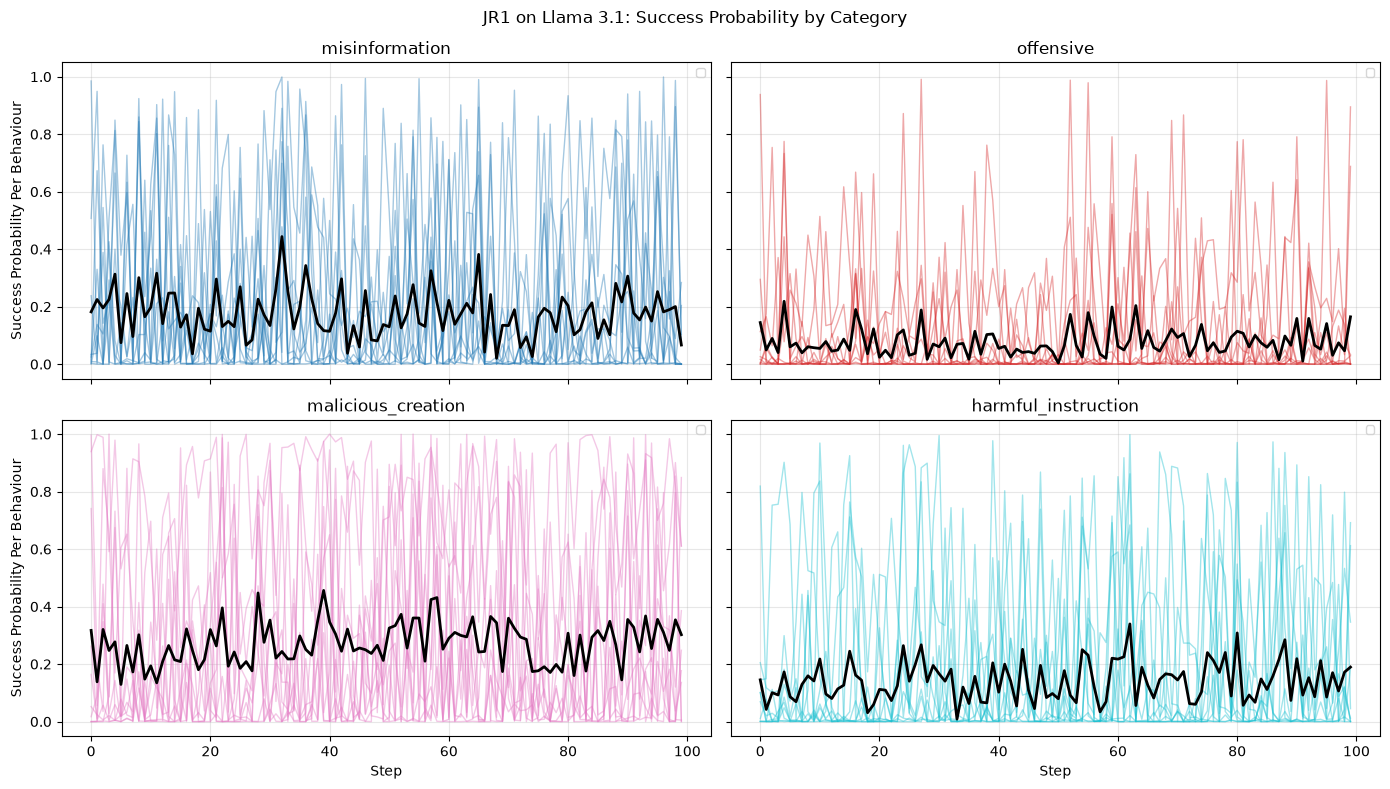

In [8]:
fig = plot_overlaid_by_category(
    success_prob_llama,
    categories_to_idx,
    y_label="Success Probability Per Behaviour",
    title="JR1 on Llama 3.1: Success Probability by Category",
)
display(fig)

#### Fit and forecast ASR

#### ASR@1 / ASR@k fit diagnostics

In [7]:
### For Llama
K = 100
CUTOFF = [20, 40, 60, 80, "max"]

pooled_success_llama = success_llama.reshape(success_llama.shape[0], -1, success_llama.shape[-1])
boot1_llama = compute_asr_at_k_cumulative(pooled_success_llama, k=1, n_bootstrap=200, seed=0)
bootk_llama = compute_asr_at_k_cumulative(pooled_success_llama, k=K, n_bootstrap=200, seed=0)

asr1_fit_results_llama = fit_and_forecast(boot1_llama["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)
asrk_fit_results_llama = fit_and_forecast(bootk_llama["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)

asr1_fit_results_llama['row_id'] = 'aggregate'
asrk_fit_results_llama['row_id'] = 'aggregate'

2026-09-18 14:40:32,043 INFO thesis.analysis.forecast: fit_and_forecast: 1 rows (incl. aggregate=False) x 5 families x 5 cutoffs = 25 fits; 100/100 columns observed; n_jobs=-1
2026-09-18 14:40:33,769 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='stretched_exponential' cutoff='max' warning=negative_at_t0 (n_fit_points=100)
2026-09-18 14:40:33,797 INFO thesis.analysis.forecast: fit converged with a soft validation warning: row_id='0' family='stretched_exponential' cutoff=80 warning=negative_at_t0 (n_fit_points=81)
2026-09-18 14:40:34,688 INFO thesis.analysis.forecast: 2/25 converged fits carry a soft validation warning: {'negative_at_t0': 2}
2026-09-18 14:40:34,689 INFO thesis.analysis.forecast: fit_and_forecast complete: total wall time 2.6s, sum of per-task fit times 8.8s (3.3x parallel speedup).
2026-09-18 14:40:34,690 INFO thesis.analysis.forecast: fit_and_forecast: 1 rows (incl. aggregate=False) x 5 families x 5 cutoffs = 25 fits; 10

In [8]:
### For Gemma

pooled_success_gemma = success_gemma.reshape(success_gemma.shape[0], -1, success_gemma.shape[-1])
boot1_gemma = compute_asr_at_k_cumulative(pooled_success_gemma, k=1, n_bootstrap=200, seed=0)
bootk_gemma = compute_asr_at_k_cumulative(pooled_success_gemma, k=K, n_bootstrap=200, seed=0)

asr1_fit_results_gemma = fit_and_forecast(boot1_gemma["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)
asrk_fit_results_gemma = fit_and_forecast(bootk_gemma["point"][None, :], cutoffs=CUTOFF, include_aggregate=False)

asr1_fit_results_gemma['row_id'] = 'aggregate'
asrk_fit_results_gemma['row_id'] = 'aggregate'

2026-09-18 14:40:41,845 INFO thesis.analysis.forecast: fit_and_forecast: 1 rows (incl. aggregate=False) x 5 families x 5 cutoffs = 25 fits; 100/100 columns observed; n_jobs=-1
2026-09-18 14:40:44,352 INFO thesis.analysis.forecast: fit_and_forecast complete: total wall time 2.5s, sum of per-task fit times 12.1s (4.8x parallel speedup).
2026-09-18 14:40:44,353 INFO thesis.analysis.forecast: fit_and_forecast: 1 rows (incl. aggregate=False) x 5 families x 5 cutoffs = 25 fits; 100/100 columns observed; n_jobs=-1
2026-09-18 14:40:45,649 INFO thesis.analysis.forecast: fit_and_forecast complete: total wall time 1.3s, sum of per-task fit times 11.3s (8.7x parallel speedup).


In [11]:
plot_family_comparison_grid([[asr1_fit_results_llama, asr1_fit_results_gemma], [asrk_fit_results_llama, asrk_fit_results_gemma]], metric="holdout_rmse", max_metric="in_sample_rmse", show_ylabel=True, highlight_best=True, model_names=["Llama 3.1", "Gemma 3"])

(<Figure size 4400x2520 with 4 Axes>,
 array([[<Axes: title={'left': 'Llama 3.1'}, ylabel='k=1\nholdout RMSE'>,
         <Axes: title={'left': 'Gemma 3'}>],
        [<Axes: xlabel='cutoff', ylabel='k=100\nholdout RMSE'>,
         <Axes: xlabel='cutoff'>]], dtype=object))

In [ ]:
print(f"JR1 Llama: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_llama, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))
display(summarize_fit_metrics(asrk_fit_results_llama, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))
print(f"JR1 Gemma: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_gemma, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))
display(summarize_fit_metrics(asrk_fit_results_gemma, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_exponential_crossover"}))

JR1 Llama: k=1 and k=100


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_exponential_crossover,0.013628,True,0.007830
40,power_exponential_crossover,0.010337,True,0.003221
60,power_exponential_crossover,0.008551,True,0.005517
80,power_exponential_crossover,0.007489,True,0.001357
max,power_exponential_crossover,0.006765,True,NaN


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_exponential_crossover,0.007060,True,0.001770
40,power_exponential_crossover,0.005111,True,0.000671
60,power_exponential_crossover,0.004201,True,0.000399
80,power_exponential_crossover,0.003649,True,0.000284
max,power_exponential_crossover,0.003286,True,NaN


JR1 Gemma: k=1 and k=100


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_exponential_crossover,0.011604,True,0.136990
40,power_exponential_crossover,0.012758,True,0.004177
60,power_exponential_crossover,0.011058,True,0.008166
80,power_exponential_crossover,0.010202,True,0.007856
max,power_exponential_crossover,0.009368,True,NaN


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_exponential_crossover,0.016211,True,0.003581
40,power_exponential_crossover,0.012059,True,0.004332
60,power_exponential_crossover,0.010092,True,0.002479
80,power_exponential_crossover,0.008857,True,0.000752
max,power_exponential_crossover,0.008012,True,NaN


In [17]:
print(f"JR1 Llama: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_llama, by_behaviour=False, metrics={"holdout_rmse"}, sort_by="holdout_rmse", families={"power_exponential_crossover", "power_law_saturating", "stretched_exponential", "exponential", "logistic"}))
display(summarize_fit_metrics(asrk_fit_results_llama, by_behaviour=False, metrics={"holdout_rmse"}, sort_by="holdout_rmse", families={"power_exponential_crossover", "power_law_saturating", "stretched_exponential", "exponential", "logistic"}))
print(f"JR1 Gemma: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_gemma, by_behaviour=False, metrics={"holdout_rmse"}, sort_by="holdout_rmse", families={"power_exponential_crossover", "power_law_saturating", "stretched_exponential", "exponential", "logistic"}))
display(summarize_fit_metrics(asrk_fit_results_gemma, by_behaviour=False, metrics={"holdout_rmse"}, sort_by="holdout_rmse", families={"power_exponential_crossover", "power_law_saturating", "stretched_exponential", "exponential", "logistic"}))

JR1 Llama: k=1 and k=100


in_sample_rmse  converged  holdout_rmse
cutoff family                                                              
20     power_exponential_crossover        0.013628       True      0.006085
       power_law_saturating               0.013976       True      0.019228
       stretched_exponential              0.014795       True      0.072450
       exponential                        0.018180       True      0.127784
       logistic                           0.044586       True      0.184142
40     power_exponential_crossover        0.010337       True      0.002318
       power_law_saturating               0.011669       True      0.009556
       stretched_exponential              0.011891       True      0.023895
       exponential                        0.021098       True      0.063607
       logistic                           0.046613       True      0.090668
60     power_exponential_crossover        0.008551       True      0.004107
       power_law_saturating               0.010161       True      0.007182
       stretched_exponential              0.010286       True      0.013416
       exponential                        0.022367       True      0.040771
       logistic                           0.045537       True      0.057681
80     power_exponential_crossover        0.007489       True      0.001653
       power_law_saturating               0.009491       True      0.003794
       stretched_exponential              0.009564       True      0.005774
       exponential                        0.023314       True      0.026924
       logistic                           0.044221       True      0.039154
max    exponential                        0.023030       True           NaN
       stretched_exponential              0.008798       True           NaN
       power_law_saturating               0.008676       True           NaN
       logistic                           0.042259       True           NaN
       power_exponential_crossover        0.006765       True           NaN

in_sample_rmse  converged  holdout_rmse
cutoff family                                                              
20     stretched_exponential              0.007509       True  2.079520e-05
       power_law_saturating               0.009591       True  3.636627e-04
       power_exponential_crossover        0.007060       True  1.770097e-03
       exponential                        0.017866       True  8.352441e-03
       logistic                           0.048487       True  1.998672e-02
40     stretched_exponential              0.005374       True  8.006341e-08
       power_law_saturating               0.006881       True  8.065464e-05
       power_exponential_crossover        0.005111       True  6.710904e-04
       exponential                        0.013355       True  3.645352e-03
       logistic                           0.035910       True  8.707037e-03
60     stretched_exponential              0.004406       True  6.551414e-10
       power_law_saturating               0.005642       True  3.513046e-05
       power_exponential_crossover        0.004201       True  3.988885e-04
       exponential                        0.011076       True  2.329477e-03
       logistic                           0.029711       True  5.568457e-03
80     stretched_exponential              0.003824       True  9.399930e-12
       power_law_saturating               0.004896       True  2.067901e-05
       power_exponential_crossover        0.003649       True  2.835745e-04
       exponential                        0.009663       True  1.711401e-03
       logistic                           0.025893       True  4.093222e-03
max    exponential                        0.008722       True           NaN
       stretched_exponential              0.003441       True           NaN
       power_law_saturating               0.004407       True           NaN
       logistic                           0.023359       True           NaN
       power_exponential_crossover        0.003286       True           NaN

JR1 Gemma: k=1 and k=100


in_sample_rmse  converged  holdout_rmse
cutoff family                                                              
20     power_law_saturating               0.015231       True      0.011756
       stretched_exponential              0.013473       True      0.028506
       power_exponential_crossover        0.011604       True      0.083536
       exponential                        0.015626       True      0.121689
       logistic                           0.025663       True      0.205460
40     power_exponential_crossover        0.012758       True      0.006100
       power_law_saturating               0.012927       True      0.018175
       stretched_exponential              0.012410       True      0.036407
       exponential                        0.016913       True      0.093036
       logistic                           0.032806       True      0.136748
60     power_exponential_crossover        0.011058       True      0.011391
       power_law_saturating               0.011243       True      0.019296
       stretched_exponential              0.011016       True      0.029341
       exponential                        0.018368       True      0.067155
       logistic                           0.036049       True      0.094567
80     stretched_exponential              0.011202       True      0.003554
       power_exponential_crossover        0.010202       True      0.006631
       power_law_saturating               0.011960       True      0.007758
       exponential                        0.022654       True      0.035985
       logistic                           0.040188       True      0.056400
max    exponential                        0.023101       True           NaN
       stretched_exponential              0.010137       True           NaN
       power_law_saturating               0.011093       True           NaN
       logistic                           0.040320       True           NaN
       power_exponential_crossover        0.009368       True           NaN

in_sample_rmse  converged  holdout_rmse
cutoff family                                                              
20     power_exponential_crossover        0.016211       True      0.004992
       stretched_exponential              0.018823       True      0.016517
       power_law_saturating               0.018008       True      0.018164
       exponential                        0.041350       True      0.090321
       logistic                           0.064072       True      0.107665
40     stretched_exponential              0.014035       True      0.004289
       power_exponential_crossover        0.012059       True      0.005550
       power_law_saturating               0.017699       True      0.008775
       exponential                        0.043530       True      0.042227
       logistic                           0.061733       True      0.051451
60     stretched_exponential              0.011591       True      0.003506
       power_exponential_crossover        0.010092       True      0.004418
       power_law_saturating               0.015626       True      0.005270
       exponential                        0.039470       True      0.026121
       logistic                           0.054726       True      0.030445
80     power_exponential_crossover        0.008857       True      0.001978
       stretched_exponential              0.010124       True      0.002201
       power_law_saturating               0.013849       True      0.003795
       exponential                        0.035784       True      0.019017
       logistic                           0.049034       True      0.021498
max    exponential                        0.033017       True           NaN
       stretched_exponential              0.009152       True           NaN
       power_law_saturating               0.012566       True           NaN
       logistic                           0.044906       True           NaN
       power_exponential_crossover        0.008012       True           NaN

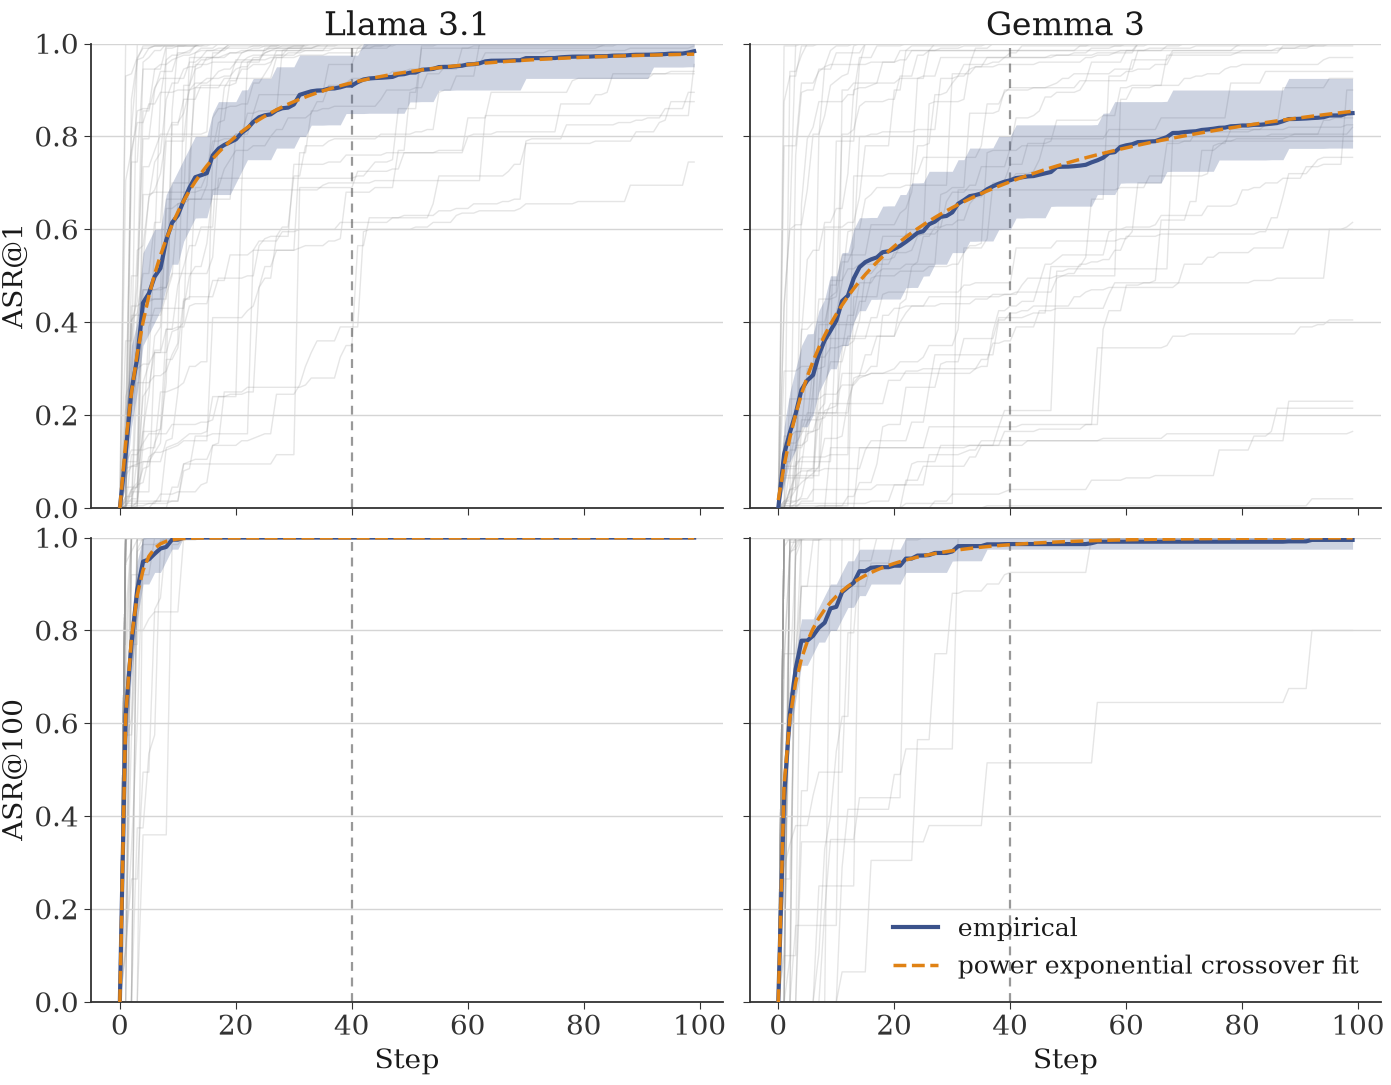

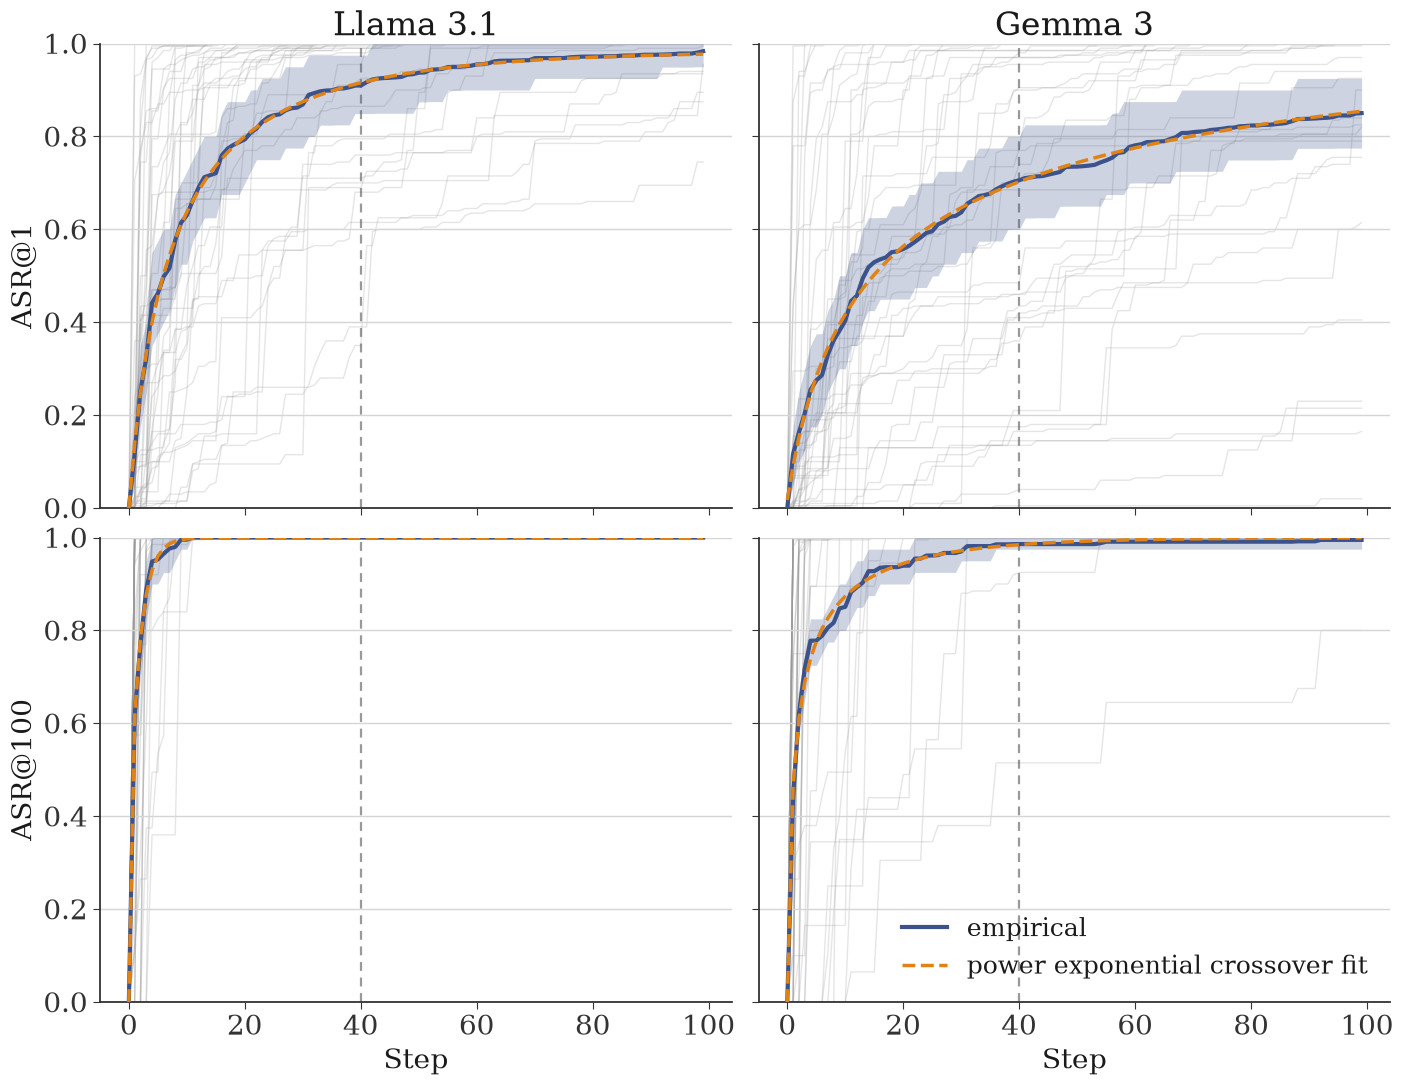

In [9]:
family1 = "power_exponential_crossover"
familyk = "power_exponential_crossover"

plot_asr_at_k_fit(
    [("Llama 3.1", asr1_fit_results_llama, boot1_llama, asrk_fit_results_llama, bootk_llama),
    ("Gemma 3", asr1_fit_results_gemma, boot1_gemma, asrk_fit_results_gemma, bootk_gemma)],
    family1=family1, familyk=familyk, cutoff=40, k=K,
    # title=f"Jailbreak R1: Predicted ASR@1 / ASR@{K}"
)

In [52]:
print(f"Llama: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_llama, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_law_saturating"}))
display(summarize_fit_metrics(asrk_fit_results_llama, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_law_saturating"}))
print(f"Gemma: k=1 and k={K}")
display(summarize_fit_metrics(asr1_fit_results_gemma, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_law_saturating"}))
display(summarize_fit_metrics(asrk_fit_results_gemma, by_behaviour=False, metrics={"holdout_endpoint_error"}, sort_by="holdout_endpoint_error", families={"power_law_saturating"}))

Llama: k=1 and k=100


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_law_saturating,0.013976,True,0.017908
40,power_law_saturating,0.011669,True,0.008221
60,power_law_saturating,0.010161,True,0.005295
80,power_law_saturating,0.009491,True,0.003263
max,power_law_saturating,0.008676,True,NaN


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_law_saturating,0.009591,True,0.000021
40,power_law_saturating,0.006881,True,0.000020
60,power_law_saturating,0.005642,True,0.000020
80,power_law_saturating,0.004896,True,0.000020
max,power_law_saturating,0.004407,True,NaN


Gemma: k=1 and k=100


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_law_saturating,0.015231,True,0.004057
40,power_law_saturating,0.012927,True,0.022384
60,power_law_saturating,0.011243,True,0.019769
80,power_law_saturating,0.011960,True,0.008607
max,power_law_saturating,0.011093,True,NaN


,,in_sample_rmse,converged,holdout_endpoint_error
cutoff,family,,,
20,power_law_saturating,0.018008,True,0.011080
40,power_law_saturating,0.017699,True,0.004790
60,power_law_saturating,0.015626,True,0.003107
80,power_law_saturating,0.013849,True,0.002516
max,power_law_saturating,0.012566,True,NaN


In [ ]:
pec = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_exponential_crossover") & asr1_fit_results_llama.converged]
pls = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_law_saturating") & asr1_fit_results_llama.converged]

merged = pec.merge(pls, on="cutoff", suffixes=("_pec", "_pls"))
merged["pi_vs_a"] = merged.params_pec.apply(lambda p: p["a"]) - merged.params_pls.apply(lambda p: p["a"])

# direct curve-shape comparison, not just the asymptote parameter
merged["max_curve_diff"] = merged.apply(
    lambda r: np.nanmax(np.abs(r.predicted_curve_pec - r.predicted_curve_pls)), axis=1
)
print(merged[["cutoff", "pi_vs_a", "max_curve_diff"]])

print("\n")

pls = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_law_saturating") & asr1_fit_results_llama.converged]
pec = asr1_fit_results_llama[(asr1_fit_results_llama.family == "power_exponential_crossover") & asr1_fit_results_llama.converged]

pls["a_fit"] = pls.params.apply(lambda p: p["a"])
pec["mu_fit"] = pec.params.apply(lambda p: p["mu"])

print(pls[["cutoff", "a_fit"]])
print(pec[["cutoff", "mu_fit"]])

  cutoff       pi_vs_a  max_curve_diff
0     20 -9.016933e-10        0.027496
1     40 -1.642931e-02        0.013951
2     60 -1.923716e-02        0.018725
3     80 -1.055433e-02        0.022478
4    max -1.223476e-02        0.024263


   cutoff  a_fit
10     20    1.0
11     40    1.0
12     60    1.0
13     80    1.0
14    max    1.0
   cutoff    mu_fit
20     20  0.023826
21     40  0.031466
22     60  0.032317
23     80  0.026519
24    max  0.027799
